# **TP1: CNN et classification d’images**

---



# ***A - Chargement et visualisation***

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3248s 19us/step
Train: (50000, 32, 32, 3) Test: (10000, 32, 32, 3)


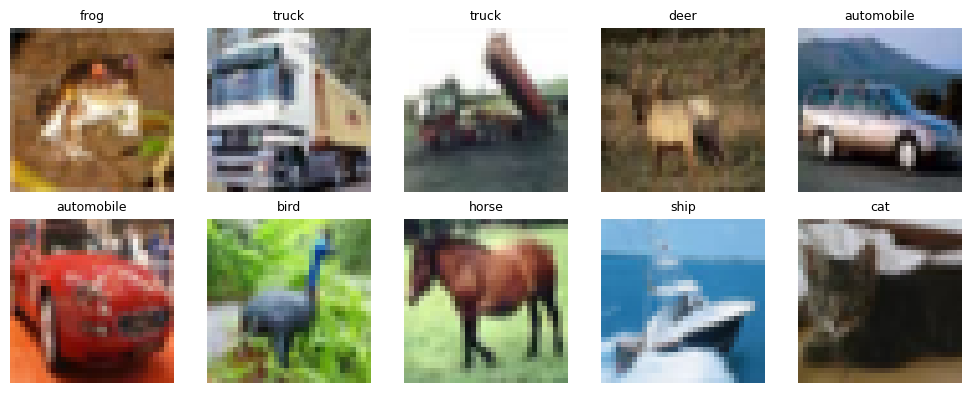

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

class_names = ("airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck")

y_train = y_train.squeeze()
y_test = y_test.squeeze()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Train:", x_train.shape, "Test:", x_test.shape)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i])
    ax.set_title(class_names[int(y_train[i])], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Nombre de classes: 10**
Forme de x_train: (50000, 32, 32, 3)
la différence entre  x_train w y_train: x_train sont les images (les entrées), y_train sont les labels 0 à 9 (les réponses). (❁´◡`❁)

#  B - Construction et entraînement

# **B1: Construction**

In [2]:
def build_model(kernel_size=3, lr=1e-3):
    model = models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, kernel_size, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(64, kernel_size, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax"),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

tf.keras.utils.set_random_seed(42)
model = build_model(3, 1e-3)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 282,250 (1.08 MB)

 Trainable params: 282,250 (1.08 MB)

 Non-trainable params: 0 (0.00 B)

Le modèle est de type Sequential et compte 282 250 paramètres, tous entraînables (0 paramètre non entraînable), soit environ 1,08 Mo.

conv2d (32 filtres 3 x 3) : sortie (32, 32, 32), 896 paramètres (3 x 3 x 3 x 32 + 32).
max_pooling2d : sortie (16, 16, 32), 0 paramètre.
conv2d_1 (64 filtres 3 x 3) : sortie (16, 16, 64), 18 496 paramètres (3 x 3 x 32 x 64 + 64).
max_pooling2d_1 : sortie (8, 8, 64), 0 paramètre.
flatten : vecteur de 8 x 8 x 64 = 4096 valeurs, 0 paramètre.
dense (64 neurones) : 262 208 paramètres (4096 x 64 + 64).
dropout : sortie (64), 0 paramètre (il ne fait que désactiver des neurones pendant l’entraînement).
dense_1 (10 neurones, softmax) : 650 paramètres (64 x 10 + 10).

Le padding “same” conserve la taille spatiale dans les convolutions (32 x 32 et 16 x 16), et c’est le MaxPooling qui la divise par 2. La couche Dense(64) concentre environ 93 % des paramètres, car elle reçoit les 4096 valeurs du Flatten. Les couches convolutives, grâce au partage des poids, en utilisent très peu. Les couches de pooling, Flatten et Dropout n’ont aucun paramètre à apprendre.


# **B2: Entraînement**

In [3]:
history = model.fit(
    x_train[:20000], y_train[:20000],
    epochs=5, batch_size=64, validation_split=0.20,
    verbose=1,
)

Epoch 1/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.2873 - loss: 1.9265 - val_accuracy: 0.4710 - val_loss: 1.5101
Epoch 2/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4317 - loss: 1.5527 - val_accuracy: 0.5058 - val_loss: 1.3567
Epoch 3/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4774 - loss: 1.4306 - val_accuracy: 0.5600 - val_loss: 1.2616
Epoch 4/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5104 - loss: 1.3451 - val_accuracy: 0.5813 - val_loss: 1.1898
Epoch 5/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5433 - loss: 1.2694 - val_accuracy: 0.5995 - val_loss: 1.1373


20 000 images (16 000 train / 4 000 validation), 5 epochs, batch size 64. Le jeu de test reste isolé.

# **Questions de compréhension**

---



**1. Justifier padding="same", ReLU et MaxPooling2D**

padding="same"
Le padding “same” ajoute des zéros autour de l’image avant la convolution. Ainsi, la taille spatiale de la sortie reste identique à celle de l’entrée (32 x 32 reste 32 x 32). Cela permet de ne pas perdre d’information sur les bords de l’image et de contrôler la réduction de taille uniquement avec le pooling.

ReLU
ReLU (f(x) = max(0, x)) introduit une non-linéarité, indispensable pour que le réseau apprenne des motifs complexes (sans elle, empiler des couches équivaudrait à une seule transformation linéaire). Elle est simple et rapide à calculer, et elle limite le problème de disparition du gradient.

MaxPooling2D(pool_size=2)
Le max pooling divise par 2 la taille des cartes de caractéristiques (32 x 32 devient 16 x 16, puis 8 x 8) en gardant la valeur maximale de chaque zone 2 x 2. Cela réduit le nombre de calculs et de paramètres, limite le surapprentissage et apporte une certaine invariance aux petits déplacements de l’objet dans l’image.

**2. Pourquoi 10 neurones avec softmax dans la dernière couche ?**

Le problème comporte 10 classes (airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck), donc il faut un neurone de sortie par classe. La fonction softmax transforme les 10 sorties en probabilités comprises entre 0 et 1 dont la somme vaut 1. La classe prédite est celle qui a la probabilité la plus élevée. Softmax est adaptée à la classification multiclasse où une image appartient à une seule classe, et elle se combine avec sparse_categorical_crossentropy pour des étiquettes entières de 0 à 9.

**3. Que mesure validation_split=0.20 ?**

Il réserve 20 % des données d’entraînement (ici 4 000 images sur 20 000) qui ne servent pas à ajuster les poids. À la fin de chaque epoch, le modèle est évalué sur ces données pour mesurer val_accuracy et val_loss. Cela permet d’estimer sa capacité de généralisation sur des données jamais vues et de détecter le surapprentissage (écart entre les performances d’entraînement et de validation). Le reste (16 000 images) sert à l’entraînement.

**4. Quel jeu de données ne doit pas servir à sélectionner les hyperparamètres ?**

Le jeu de test. Les hyperparamètres (taille du noyau, learning rate, etc.) doivent être choisis uniquement avec le jeu de validation. Le jeu de test doit rester isolé et n’être utilisé qu’une seule fois, à la fin, sur le modèle retenu. S’il servait aussi au choix du modèle, l’accuracy obtenue serait trop optimiste et ne reflèterait plus la vraie performance en généralisation.

# **B3: Courbes**

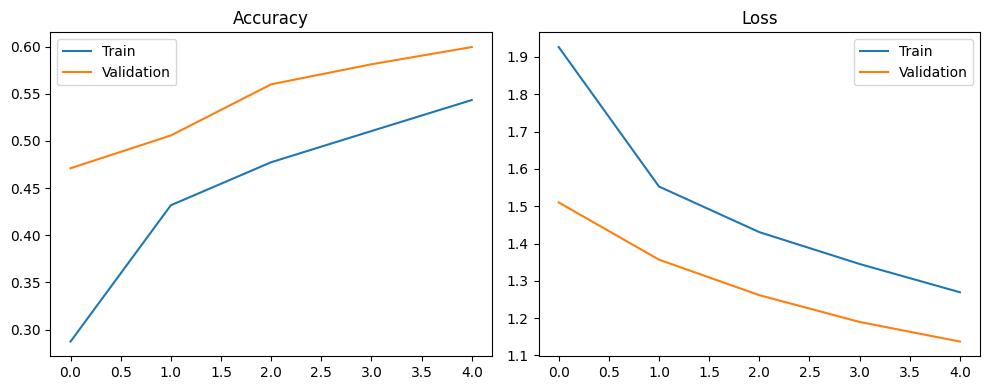

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(history.history["accuracy"], label="Train")
ax[0].plot(history.history["val_accuracy"], label="Validation")
ax[0].set_title("Accuracy")
ax[0].legend()
ax[1].plot(history.history["loss"], label="Train")
ax[1].plot(history.history["val_loss"], label="Validation")
ax[1].set_title("Loss")
ax[1].legend()
plt.tight_layout()
plt.show()

L’accuracy d’entraînement passe de 0,29 à 0,54 et celle de validation de 0,47 à 0,60. La loss d’entraînement diminue de 1,93 à 1,27 et celle de validation de 1,51 à 1,14. Les deux courbes évoluent dans le même sens et ne divergent pas : il n’y a pas de surapprentissage. La validation est même au-dessus de l’entraînement, car le Dropout est actif pendant l’entraînement (pas pendant la validation) et les métriques d’entraînement sont moyennées sur toute l’epoch, alors que le modèle s’améliore. Les courbes montent encore à la 5e epoch : le modèle est en sous-apprentissage et progresserait avec plus d’epochs.

# **B4: Les 3 variantes (tableau)**

In [5]:
variantes = [("A - référence", 3, 1e-3),
             ("B - noyaux 5x5", 5, 1e-3),
             ("C - lr réduit", 3, 1e-4)]

results = {}
trained = {}

for name, k, lr in variantes:
    tf.keras.utils.set_random_seed(42)
    m = build_model(k, lr)
    h = m.fit(x_train[:20000], y_train[:20000],
              epochs=5, batch_size=64, validation_split=0.20, verbose=0)
    va, vl = h.history["val_accuracy"][-1], h.history["val_loss"][-1]
    results[name] = (va, vl)
    trained[name] = m
    print(f"{name}: val_accuracy={va:.3f} | val_loss={vl:.3f}")

A - référence: val_accuracy=0.602 | val_loss=1.159
B - noyaux 5x5: val_accuracy=0.573 | val_loss=1.223
C - lr réduit: val_accuracy=0.474 | val_loss=1.516


La variante A est la meilleure (val. accuracy 0,602, val. loss 1,159). Les noyaux 5 x 5 (B) dégradent légèrement les résultats : ils ont plus de paramètres et ne sont pas plus efficaces sur 5 epochs. Avec un learning rate de 1e-4 (C), l’apprentissage est trop lent : en 5 epochs, le modèle n’a pas eu le temps de converger (0,474).

# ***Évaluation finale***

In [6]:
best = max(results, key=lambda n: results[n][0])
print("Meilleure variante:", best)

test_loss, test_accuracy = trained[best].evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_accuracy:.3f}")

Meilleure variante: A - référence
Test accuracy: 0.592


La variante A, choisie sur la validation, est évaluée une seule fois sur le jeu de test : test accuracy = 0,592.

# 7. Conclusion

Le CNN atteint 59,2 % de test accuracy, contre 60,2 % en validation : l’écart est d’environ 1 point, donc le modèle généralise correctement. L’écart entre entraînement et validation reste faible et le Dropout limite le surapprentissage. La variante A (3 x 3, lr = 1e-3) est la meilleure ; les noyaux 5 x 5 n’apportent rien et un lr de 1e-4 est trop lent sur 5 epochs. Les performances restent modestes, car on utilise seulement 20 000 images, 5 epochs et une architecture simple. Pour progresser : plus d’epochs et de données, data augmentation, batch normalization.